##  Feature Selection and Model Development

### Project
Rice Variety Classification and Quality-Control Decision Support

### Handover from Person 2
Person 2 completed data-quality validation, outlier investigation,
stratified train/test splitting and scaling analysis.

This stage uses the prepared training dataset to investigate
feature selection, compare classification models and select
a suitable model using cross-validation.

The reserved test dataset will not be used for model selection.

In [2]:
# Step 1: Load Person 2's training dataset

import pandas as pd

train_df = pd.read_csv("rice_train.csv")

X_train = train_df.drop(columns=["Class"])
y_train = train_df["Class"]

print("Training dataset:", train_df.shape)
print("Input features:", X_train.shape)
print("Target labels:", y_train.shape)

display(train_df.head())

Training dataset: (3048, 8)
Input features: (3048, 7)
Target labels: (3048,)


,Area,Perimeter,Major_Axis_Length,Minor_Axis_Length,Eccentricity,Convex_Area,Extent,Class
0,13078.0,452.990997,183.978973,91.690010,0.866963,13385.0,0.732743,Osmancik
1,15381.0,503.579010,211.883530,93.309746,0.897810,15749.0,0.740325,Cammeo
2,11280.0,420.101013,170.670364,85.497368,0.865476,11582.0,0.643175,Osmancik
3,12408.0,454.390991,191.896530,83.033478,0.901538,12664.0,0.583906,Osmancik
4,14131.0,490.700989,206.926666,88.284050,0.904420,14519.0,0.752931,Cammeo


In [3]:
# Step 2: Forward Feature Selection

from sklearn.feature_selection import SequentialFeatureSelector
from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import StratifiedKFold

# Model pipeline
pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Five-fold stratified cross-validation
cv = StratifiedKFold(
    n_splits=5,
    shuffle=True,
    random_state=42
)

# Forward selection: select 2 features
forward_selector = SequentialFeatureSelector(
    estimator=pipeline,
    n_features_to_select=2,
    direction="forward",
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

forward_selector.fit(X_train, y_train)

selected_forward = X_train.columns[
    forward_selector.get_support()
].tolist()

print("Forward Selected Features:")
print(selected_forward)

Forward Selected Features:
['Perimeter', 'Major_Axis_Length']


## Forward Feature Selection

Forward selection was applied to the training dataset
using Logistic Regression with StandardScaler.

Five-fold stratified cross-validation and classification
accuracy were used to evaluate candidate features.

Two features were selected for this initial experiment.
The selected subset will later be compared with other
feature-selection approaches.

In [4]:
# Step 3: Backward Feature Selection

backward_selector = SequentialFeatureSelector(
    estimator=pipeline,
    n_features_to_select=5,
    direction="backward",
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

backward_selector.fit(X_train, y_train)

selected_backward = X_train.columns[
    backward_selector.get_support()
].tolist()

print("Backward Selected Features:")
print(selected_backward)

Backward Selected Features:
['Perimeter', 'Major_Axis_Length', 'Eccentricity', 'Convex_Area', 'Extent']


In [5]:
# Step 4: Compare Feature Selection Methods

from sklearn.model_selection import cross_val_score

feature_sets = {
    "All 7 Features": X_train.columns.tolist(),
    "Forward Selection": selected_forward,
    "Backward Selection": selected_backward
}

results = []

for method, features in feature_sets.items():

    scores = cross_val_score(
        pipeline,
        X_train[features],
        y_train,
        cv=cv,
        scoring="accuracy",
        n_jobs=-1
    )

    results.append({
        "Method": method,
        "Number of Features": len(features),
        "Mean CV Accuracy": scores.mean(),
        "CV Std": scores.std()
    })

comparison_df = pd.DataFrame(results)

display(comparison_df)

,Method,Number of Features,Mean CV Accuracy,CV Std
0,All 7 Features,7,0.933068,0.009728
1,Forward Selection,2,0.933723,0.009689
2,Backward Selection,5,0.933396,0.009107


### Feature Selection Comparison — Findings

Three feature sets were compared using Logistic Regression
with five-fold stratified cross-validation.

- All 7 features achieved 93.31% mean CV accuracy.
- Forward selection achieved 93.37% using only 2 features.
- Backward selection achieved 93.34% using 5 features.

Forward selection produced the highest observed accuracy
while requiring the fewest measurements.

However, the differences were very small and do not
demonstrate a statistically significant improvement.

The results are exploratory because feature selection
was performed before this cross-validation comparison.

The two-feature subset will be retained as a candidate
for further model comparison.

In [6]:
# Step 5: PCA — Explained Variance

from sklearn.decomposition import PCA
from sklearn.preprocessing import StandardScaler

# Fit scaling and PCA on training data only
pca_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA())
])

pca_pipeline.fit(X_train)

pca = pca_pipeline.named_steps["pca"]

pca_results = pd.DataFrame({
    "Component": [
        f"PC{i+1}" for i in range(len(pca.explained_variance_ratio_))
    ],
    "Explained Variance": pca.explained_variance_ratio_,
    "Cumulative Variance": pca.explained_variance_ratio_.cumsum()
})

display(pca_results)

,Component,Explained Variance,Cumulative Variance
0,PC1,0.654274,0.654274
1,PC2,0.215027,0.869301
2,PC3,0.127767,0.997068
3,PC4,0.001695,0.998763
4,PC5,0.000880,0.999643
5,PC6,0.000295,0.999938
6,PC7,0.000062,1.000000


In [7]:
# Step 6: Evaluate PCA with Logistic Regression

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.decomposition import PCA
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import cross_val_score

# PCA + Logistic Regression pipeline
pca_model = Pipeline([
    ("scaler", StandardScaler()),
    ("pca", PCA(n_components=3)),
    ("model", LogisticRegression(max_iter=1000))
])

# Five-fold cross-validation
pca_scores = cross_val_score(
    pca_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("PCA Components: 3")
print("Mean CV Accuracy:", round(pca_scores.mean(), 4))
print("CV Standard Deviation:", round(pca_scores.std(), 4))

PCA Components: 3
Mean CV Accuracy: 0.9318
CV Standard Deviation: 0.0089


## Final Feature Selection Method Comparison

| Method | Features / Components | CV Accuracy |
|---|---:|---:|
| All Original Features | 7 | 93.31% |
| Forward Selection | 2 | **93.37%** |
| Backward Selection | 5 | 93.34% |
| PCA | 3 | 93.18% |

### Conclusion

Forward Selection achieved the highest observed cross-validation
accuracy (93.37%) using only two features: Perimeter and
Major_Axis_Length.

Although all methods produced similar accuracy, Forward Selection
was preferred for further model development because it uses fewer
measurements and retains direct feature interpretability.

These exploratory results do not establish a statistically
significant performance advantage.

## Machine Learning Model Development

### Baseline Classification

A Dummy Classifier was used to establish a baseline
for rice variety classification.

The most-frequent strategy predicts the majority class
for every observation.

This provides a reference for evaluating whether more
advanced classification algorithms offer meaningful
improvements over a simple prediction strategy.

In [8]:
# Majority-Class Baseline

from sklearn.dummy import DummyClassifier
from sklearn.model_selection import cross_val_score

baseline_model = DummyClassifier(strategy="most_frequent")

baseline_scores = cross_val_score(
    baseline_model,
    X_train,
    y_train,
    cv=cv,
    scoring="accuracy",
    n_jobs=-1
)

print("Baseline Model: Dummy Classifier")
print("Mean CV Accuracy:", round(baseline_scores.mean(), 4))
print("CV Standard Deviation:", round(baseline_scores.std(), 4))

Baseline Model: Dummy Classifier
Mean CV Accuracy: 0.5722
CV Standard Deviation: 0.0005


### Logistic Regression Model

Logistic Regression was selected as the first supervised
classification algorithm for predicting rice variety.

The model uses the two features identified through
forward selection: Perimeter and Major_Axis_Length.

StandardScaler is included in a pipeline to standardize
the features separately within each cross-validation fold.

Five-fold stratified cross-validation is used to estimate
classification performance on the training data.

In [12]:
# Logistic Regression Model

from sklearn.linear_model import LogisticRegression
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline
from sklearn.model_selection import cross_validate

# Use the two forward-selected features
X_train_selected = X_train[selected_forward]

# Create Logistic Regression pipeline
lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Evaluate using multiple metrics
lr_scores = cross_validate(
    lr_model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

print("Logistic Regression Results")
print("---------------------------")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    mean_score = lr_scores[f"test_{metric}"].mean()
    print(f"{metric}: {mean_score:.4f}")

Logistic Regression Results
---------------------------
accuracy: 0.9337
precision: 0.9329
recall: 0.9319
f1: 0.9323
roc_auc: 0.9793


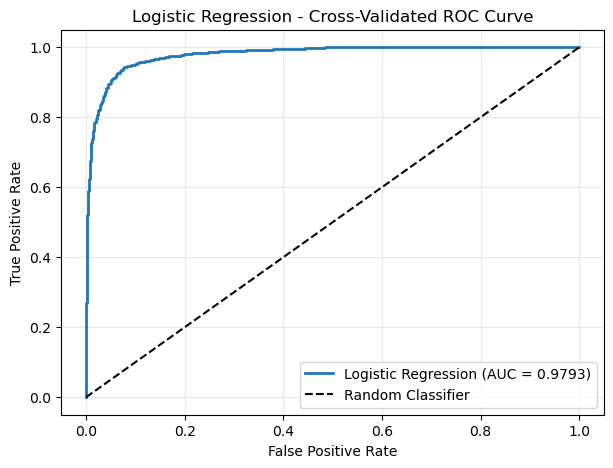

Out-of-fold ROC-AUC: 0.9793


In [11]:
# Logistic Regression ROC Curve

import matplotlib.pyplot as plt
from sklearn.model_selection import cross_val_predict
from sklearn.metrics import roc_curve, roc_auc_score

# Get out-of-fold predicted probabilities
y_prob = cross_val_predict(
    lr_model,
    X_train_selected,
    y_train,
    cv=cv,
    method="predict_proba",
    n_jobs=-1
)

# Identify probability column for Osmancik
lr_model.fit(X_train_selected, y_train)

class_names = lr_model.named_steps["model"].classes_
positive_index = list(class_names).index("Osmancik")

osmancik_prob = y_prob[:, positive_index]

# Convert true labels into binary labels
y_binary = (y_train == "Osmancik").astype(int)

# Calculate ROC curve and AUC
fpr, tpr, thresholds = roc_curve(
    y_binary,
    osmancik_prob
)

auc_value = roc_auc_score(
    y_binary,
    osmancik_prob
)

# Plot ROC curve
plt.figure(figsize=(7, 5))

plt.plot(
    fpr,
    tpr,
    label=f"Logistic Regression (AUC = {auc_value:.4f})",
    linewidth=2
)

plt.plot(
    [0, 1],
    [0, 1],
    "k--",
    label="Random Classifier"
)

plt.xlabel("False Positive Rate")
plt.ylabel("True Positive Rate")
plt.title("Logistic Regression - Cross-Validated ROC Curve")
plt.legend(loc="lower right")
plt.grid(alpha=0.3)

plt.show()

print("Out-of-fold ROC-AUC:", round(auc_value, 4))

### Logistic Regression Performance

| Metric | Cross-Validation Score |
|---|---:|
| Accuracy | 93.37% |
| Precision (Macro) | 93.29% |
| Recall (Macro) | 93.19% |
| F1-Score (Macro) | 93.23% |
| ROC-AUC | 97.93% |

**Interpretation:**

Logistic Regression demonstrated strong classification
performance using only Perimeter and Major_Axis_Length.

The model achieved 93.37% mean cross-validation accuracy
and 97.93% ROC-AUC.

These findings suggest that two morphological measurements
can provide useful information for distinguishing Cammeo
and Osmancik rice varieties.

However, these are exploratory cross-validation results
because feature selection was conducted before model
evaluation. Final performance must be assessed using
the reserved test dataset.

In [13]:
# K-Nearest Neighbors Classification

from sklearn.neighbors import KNeighborsClassifier
from sklearn.model_selection import cross_validate

knn_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier(n_neighbors=5))
])

knn_scores = cross_validate(
    knn_model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

print("KNN Results")
print("-----------")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(
        f"{metric}: "
        f"{knn_scores[f'test_{metric}'].mean():.4f}"
    )

KNN Results
-----------
accuracy: 0.9245
precision: 0.9236
recall: 0.9226
f1: 0.9229
roc_auc: 0.9560


In [14]:
# KNN Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from sklearn.neighbors import KNeighborsClassifier
from sklearn.preprocessing import StandardScaler
from sklearn.pipeline import Pipeline

# Create KNN pipeline
knn_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", KNeighborsClassifier())
])

# Values of K to investigate
param_grid = {
    "model__n_neighbors": [1, 3, 5, 7, 9, 11, 13, 15, 17, 19, 21]
}

# Grid search with cross-validation
knn_grid = GridSearchCV(
    estimator=knn_pipeline,
    param_grid=param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

# Train using only the training dataset
knn_grid.fit(X_train_selected, y_train)

print("Best K:", knn_grid.best_params_["model__n_neighbors"])
print("Best CV Accuracy:", round(knn_grid.best_score_, 4))

Best K: 19
Best CV Accuracy: 0.9321


In [15]:
# Optimized KNN Evaluation

best_knn_model = knn_grid.best_estimator_

optimized_knn_scores = cross_validate(
    best_knn_model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

print("Optimized KNN Results (K = 19)")
print("--------------------------------")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    mean_score = optimized_knn_scores[f"test_{metric}"].mean()
    print(f"{metric}: {mean_score:.4f}")

Optimized KNN Results (K = 19)
--------------------------------
accuracy: 0.9321
precision: 0.9313
recall: 0.9302
f1: 0.9306
roc_auc: 0.9724


### KNN Hyperparameter Tuning Results

| Configuration | K Value | Mean CV Accuracy |
|---|---:|---:|
| Initial KNN | 5 | 92.45% |
| Optimized KNN | 19 | 93.21% |
| Logistic Regression | N/A | 93.37% |

GridSearchCV identified K = 19 as the best value among
the eleven candidate values tested.

The optimized KNN improved mean cross-validation
accuracy from 92.45% to 93.21%.

Logistic Regression still achieved slightly higher
observed accuracy using the same selected features.

The tuning results are exploratory. The reserved
test dataset was not used.

In [17]:
# Decision Tree - 2 Features vs All 7 Features

from sklearn.tree import DecisionTreeClassifier
from sklearn.model_selection import cross_validate
import pandas as pd

feature_options = {
    "Selected 2 Features": X_train_selected,
    "All 7 Features": X_train
}

dt_comparison = []

for name, X_data in feature_options.items():

    model = DecisionTreeClassifier(
        max_depth=5,
        random_state=42
    )

    scores = cross_validate(
        model,
        X_data,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision_macro",
            "recall": "recall_macro",
            "f1": "f1_macro",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    dt_comparison.append({
        "Feature Set": name,
        "Number of Features": X_data.shape[1],
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

dt_comparison_df = pd.DataFrame(dt_comparison)

display(dt_comparison_df.round(4))

,Feature Set,Number of Features,Accuracy,Precision,Recall,F1,ROC-AUC
0,Selected 2 Features,2,0.9242,0.9225,0.9231,0.9227,0.9656
1,All 7 Features,7,0.9199,0.9182,0.9192,0.9184,0.9621


### Decision Tree Feature Comparison

| Metric | Selected 2 Features | All 7 Features |
|---|---:|---:|
| Number of Features | 2 | 7 |
| Accuracy | **92.42%** | 91.99% |
| Precision (Macro) | **92.25%** | 91.82% |
| Recall (Macro) | **92.31%** | 91.92% |
| F1-Score (Macro) | **92.27%** | 91.84% |
| ROC-AUC | **96.56%** | 96.21% |

### Interpretation

The Decision Tree using two selected features achieved
92.42% cross-validation accuracy, compared with 91.99%
using all seven features.

The two-feature configuration showed slightly higher
performance across all five evaluation metrics.

Therefore, the two-feature Decision Tree was retained
as the preferred candidate for further comparison.

These results are exploratory and do not establish
that the smaller feature set is statistically superior.

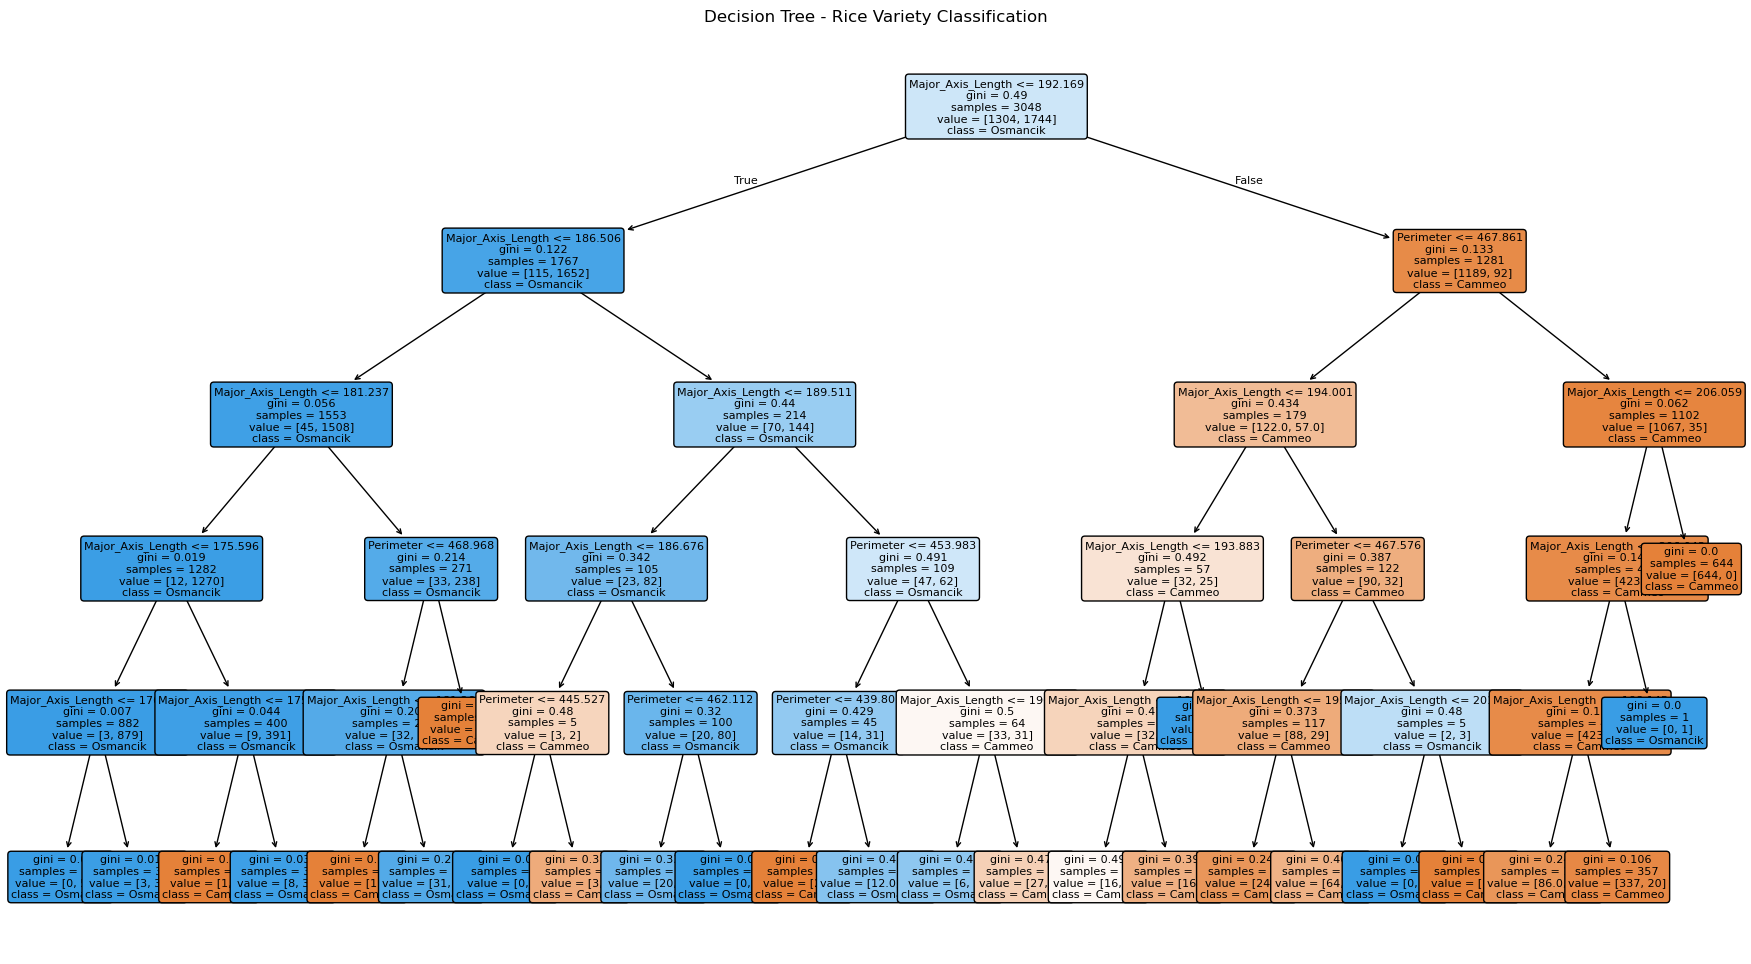

In [19]:
# Step 7.4.2: Train and Visualize Decision Tree

import matplotlib.pyplot as plt
from sklearn.tree import DecisionTreeClassifier, plot_tree

# Create Decision Tree using the selected 2 features
dt_model = DecisionTreeClassifier(
    max_depth=5,
    random_state=42
)

# Train the Decision Tree
dt_model.fit(X_train_selected, y_train)

# Visualize the Decision Tree
plt.figure(figsize=(22, 12))

plot_tree(
    dt_model,
    feature_names=X_train_selected.columns.tolist(),
    class_names=dt_model.classes_.tolist(),
    filled=True,
    rounded=True,
    fontsize=8
)

plt.title("Decision Tree - Rice Variety Classification")
plt.show()

### Decision Tree Visualization — Interpretation

The Decision Tree was trained using Perimeter and
Major_Axis_Length with a maximum depth of five.

Major_Axis_Length was selected for the root split,
indicating its importance in the tree's initial
classification decision.

The model uses additional splits involving both
measurements to distinguish Cammeo and Osmancik.

The visualization demonstrates the interpretability
of Decision Trees, although deeper trees become
more difficult to understand.

A simplified visualization was also produced to
highlight the main decision rules.

### Random Forest Classification

Random Forest was evaluated as an ensemble classification
algorithm for rice variety prediction.

The model combines multiple Decision Trees to produce
classification predictions.

An initial configuration of 100 trees and a maximum
depth of five was selected for experimentation.

The two forward-selected features were used to maintain
a consistent comparison with the previous algorithms.

Five-fold stratified cross-validation was used to
evaluate classification performance.

In [22]:
# Random Forest Classification

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import cross_validate

rf_model = RandomForestClassifier(
    n_estimators=100,
    max_depth=5,
    random_state=42,
    n_jobs=-1
)

rf_scores = cross_validate(
    rf_model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

print("Random Forest Results")
print("---------------------")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(
        f"{metric}: "
        f"{rf_scores[f'test_{metric}'].mean():.4f}"
    )

Random Forest Results
---------------------
accuracy: 0.9304
precision: 0.9292
recall: 0.9291
f1: 0.9290
roc_auc: 0.9765


In [23]:
# Step 7.6: Random Forest - Feature Set Comparison

rf_feature_sets = {
    "Selected 2 Features": X_train_selected,
    "All 7 Features": X_train
}

rf_comparison = []

for name, X_data in rf_feature_sets.items():

    scores = cross_validate(
        rf_model,
        X_data,
        y_train,
        cv=cv,
        scoring={
            "accuracy": "accuracy",
            "precision": "precision_macro",
            "recall": "recall_macro",
            "f1": "f1_macro",
            "roc_auc": "roc_auc"
        },
        n_jobs=-1
    )

    rf_comparison.append({
        "Feature Set": name,
        "Features": X_data.shape[1],
        "Accuracy": scores["test_accuracy"].mean(),
        "Precision": scores["test_precision"].mean(),
        "Recall": scores["test_recall"].mean(),
        "F1": scores["test_f1"].mean(),
        "ROC-AUC": scores["test_roc_auc"].mean()
    })

rf_comparison_df = pd.DataFrame(rf_comparison)

display(rf_comparison_df.round(4))

,Feature Set,Features,Accuracy,Precision,Recall,F1,ROC-AUC
0,Selected 2 Features,2,0.9304,0.9292,0.9291,0.9290,0.9765
1,All 7 Features,7,0.9268,0.9259,0.9249,0.9252,0.9779


### Random Forest Feature Comparison

| Metric | Selected 2 Features | All 7 Features |
|---|---:|---:|
| Number of Features | 2 | 7 |
| Accuracy | **93.04%** | 92.68% |
| Precision (Macro) | **92.92%** | 92.59% |
| Recall (Macro) | **92.91%** | 92.49% |
| F1-Score (Macro) | **92.90%** | 92.52% |
| ROC-AUC | 97.65% | **97.79%** |

### Interpretation

Random Forest was evaluated using two different feature
configurations with five-fold stratified cross-validation.

The two-feature model achieved higher accuracy (93.04%)
and F1-score (92.90%).

The seven-feature model achieved a slightly higher
ROC-AUC (97.79%).

Because the performance differences were small, the
two-feature configuration was retained provisionally
due to its simplicity and lower measurement requirements.

Further hyperparameter tuning and validation are required
before final model selection.

In [24]:
# Random Forest Hyperparameter Tuning

from sklearn.ensemble import RandomForestClassifier
from sklearn.model_selection import RandomizedSearchCV

rf_tuning_model = RandomForestClassifier(
    random_state=42,
    n_jobs=-1
)

param_distributions = {
    "n_estimators": [50, 100, 150, 200],
    "max_depth": [3, 5, 7, 10, None],
    "min_samples_split": [2, 5, 10]
}

rf_random_search = RandomizedSearchCV(
    estimator=rf_tuning_model,
    param_distributions=param_distributions,
    n_iter=15,
    scoring="accuracy",
    cv=cv,
    random_state=42,
    n_jobs=-1
)

rf_random_search.fit(X_train_selected, y_train)

print("Best Parameters:")
print(rf_random_search.best_params_)

print(
    "Best CV Accuracy:",
    round(rf_random_search.best_score_, 4)
)

Best Parameters:
{'n_estimators': 50, 'min_samples_split': 2, 'max_depth': 3}
Best CV Accuracy: 0.9318


In [25]:
# Step 7.8: Evaluate Tuned Random Forest

from sklearn.model_selection import cross_validate

# Best model from RandomizedSearchCV
best_rf_model = rf_random_search.best_estimator_

# Evaluate using 5-fold cross-validation
rf_tuned_scores = cross_validate(
    best_rf_model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

print("Tuned Random Forest Results")
print("---------------------------")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    mean_score = rf_tuned_scores[f"test_{metric}"].mean()
    print(f"{metric}: {mean_score:.4f}")
    

Tuned Random Forest Results
---------------------------
accuracy: 0.9318
precision: 0.9310
recall: 0.9298
f1: 0.9303
roc_auc: 0.9777


### Support Vector Machine Classification

Support Vector Machine (SVM) was evaluated as an
additional supervised classification algorithm.

An RBF kernel was selected to investigate nonlinear
relationships between rice measurements and variety.

The model used the two forward-selected features:
Perimeter and Major_Axis_Length.

StandardScaler was included in the pipeline, and
five-fold stratified cross-validation was used to
evaluate accuracy, macro precision, macro recall,
macro F1-score and ROC-AUC.

The reserved test dataset was not used.

In [26]:
# Support Vector Machine Classification

from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.model_selection import cross_validate

# SVM pipeline
svm_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC(
        kernel="rbf",
        C=1.0,
        gamma="scale",
        random_state=42
    ))
])

# Five-fold cross-validation
svm_scores = cross_validate(
    svm_model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

print("SVM Results")
print("-----------")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(
        f"{metric}: "
        f"{svm_scores[f'test_{metric}'].mean():.4f}"
    )

SVM Results
-----------
accuracy: 0.9327
precision: 0.9320
recall: 0.9307
f1: 0.9312
roc_auc: 0.9578


In [27]:
# SVM Hyperparameter Tuning

from sklearn.model_selection import GridSearchCV
from sklearn.svm import SVC
from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler

svm_tuning_pipeline = Pipeline([
    ("scaler", StandardScaler()),
    ("model", SVC())
])

svm_param_grid = [
    {
        "model__kernel": ["linear"],
        "model__C": [0.1, 1, 10, 100]
    },
    {
        "model__kernel": ["rbf"],
        "model__C": [0.1, 1, 10, 100],
        "model__gamma": ["scale", 0.01, 0.1, 1]
    }
]

svm_grid_search = GridSearchCV(
    estimator=svm_tuning_pipeline,
    param_grid=svm_param_grid,
    scoring="accuracy",
    cv=cv,
    n_jobs=-1
)

svm_grid_search.fit(X_train_selected, y_train)

print("Best SVM Parameters:")
print(svm_grid_search.best_params_)

print("\nBest CV Accuracy:")
print(round(svm_grid_search.best_score_, 4))

Best SVM Parameters:
{'model__C': 10, 'model__gamma': 'scale', 'model__kernel': 'rbf'}

Best CV Accuracy:
0.9334


In [28]:
# Evaluate Tuned SVM

from sklearn.model_selection import cross_validate

# Retrieve the best SVM configuration
best_svm_model = svm_grid_search.best_estimator_

# Evaluate the tuned SVM
svm_tuned_scores = cross_validate(
    best_svm_model,
    X_train_selected,
    y_train,
    cv=cv,
    scoring={
        "accuracy": "accuracy",
        "precision": "precision_macro",
        "recall": "recall_macro",
        "f1": "f1_macro",
        "roc_auc": "roc_auc"
    },
    n_jobs=-1
)

print("Tuned SVM Results")
print("-----------------")

for metric in ["accuracy", "precision", "recall", "f1", "roc_auc"]:
    print(
        f"{metric}: "
        f"{svm_tuned_scores[f'test_{metric}'].mean():.4f}"
    )

Tuned SVM Results
-----------------
accuracy: 0.9334
precision: 0.9325
recall: 0.9315
f1: 0.9319
roc_auc: 0.9648


## Final Classification Model Comparison

Five machine learning algorithms were investigated:
Logistic Regression, K-Nearest Neighbors, Decision Tree,
Random Forest, and Support Vector Machine.

| Model | Accuracy | Precision | Recall | F1-Score | ROC-AUC |
|---|---:|---:|---:|---:|---:|
| Logistic Regression | **93.37%** | **93.29%** | **93.19%** | **93.23%** | **97.93%** |
| Tuned SVM (RBF) | 93.34% | 93.25% | 93.15% | 93.19% | 96.48% |
| Tuned KNN (K=19) | 93.21% | 93.13% | 93.02% | 93.06% | 97.24% |
| Tuned Random Forest | 93.18% | 93.10% | 92.98% | 93.03% | 97.77% |
| Decision Tree | 92.42% | 92.25% | 92.31% | 92.27% | 96.56% |

### Model Selection Decision

Logistic Regression was selected as the preferred
candidate based on its observed cross-validation
performance, simplicity, and interpretability.

The model uses two morphological features:
Perimeter and Major_Axis_Length.

Tuned SVM achieved nearly identical classification
accuracy, demonstrating that a more complex nonlinear
classifier did not provide a clear accuracy advantage.

These comparisons are exploratory because feature
selection and hyperparameter tuning used the training
dataset. Consequently, the reported cross-validation
scores may be optimistic.

The reserved test dataset will be used for independent
evaluation by Person 4 before the final recommendation.

In [29]:
# Step 8: Train and Save Preferred Logistic Regression Model

from sklearn.pipeline import Pipeline
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LogisticRegression
from pathlib import Path
import joblib

# Selected features
final_features = [
    "Perimeter",
    "Major_Axis_Length"
]

# Create the final pipeline
final_lr_model = Pipeline([
    ("scaler", StandardScaler()),
    ("model", LogisticRegression(max_iter=1000))
])

# Train using all training observations
final_lr_model.fit(
    X_train[final_features],
    y_train
)

# Create handover folder
output_dir = Path("person3_handover")
output_dir.mkdir(exist_ok=True)

# Save the complete trained pipeline
joblib.dump(
    final_lr_model,
    output_dir / "rice_logistic_regression.pkl"
)

# Save selected feature names
joblib.dump(
    final_features,
    output_dir / "selected_features.pkl"
)

print("Model saved successfully!")
print("Selected features:", final_features)
print("Training observations:", len(X_train))
print("Classes:", final_lr_model.classes_)
print("Saved folder:", output_dir)

Model saved successfully!
Selected features: ['Perimeter', 'Major_Axis_Length']
Training observations: 3048
Classes: ['Cammeo' 'Osmancik']
Saved folder: person3_handover


In [30]:
# Save Tuned SVM Model 

import joblib
from pathlib import Path

# Retrieve the best SVM model from GridSearchCV
final_svm_model = svm_grid_search.best_estimator_

# Train using all training observations
final_svm_model.fit(
    X_train[final_features],
    y_train
)

# Save the trained SVM pipeline
output_dir = Path("person3_handover")
output_dir.mkdir(exist_ok=True)

joblib.dump(
    final_svm_model,
    output_dir / "rice_svm_model.pkl"
)

print("Tuned SVM saved successfully!")
print("Selected features:", final_features)
print("Training observations:", len(X_train))
print("SVM parameters:", final_svm_model.named_steps["model"].get_params()["C"],
      final_svm_model.named_steps["model"].get_params()["kernel"])
print("Saved folder:", output_dir)

Tuned SVM saved successfully!
Selected features: ['Perimeter', 'Major_Axis_Length']
Training observations: 3048
SVM parameters: 10 rbf
Saved folder: person3_handover
